# Phase 7 — Classifier Selection and Training

**Purpose.** Choose and train the pair classifier that scores every candidate pair (Phase 5 features, 69 columns), using **train queries only**.
Threshold tuning and the validation-set evaluation are the next phases; this phase must not look at validation labels.

**Plan**
1. Compare model families with default settings on the Phase 5/6 hold-out (20 % of train queries): logistic regression, random forest, sklearn gradient boosting,
   LightGBM, and a small neural network (MLP — forward/back-propagation).
2. Tune the best gradient-boosting family by random search with **3-fold cross-validation grouped by query** on the 80 % fit queries.
3. Test class weighting (F0.5 is precision-heavy, so weighting matters less than the threshold, but it is cheap to check).
4. Compare tuned vs. baseline on the hold-out with a paired bootstrap; check probability calibration.
5. Retrain the final model on **all** train queries, save it, and write validation scores (no validation labels are read here).

**Selection rules (printed below):** highest hold-out PR-AUC; if the simpler model (fewer dependencies) is within 0.001 PR-AUC, take the simpler one.
Tuned config replaces the default only if it wins on CV PR-AUC **and** does not lose on hold-out PR-AUC.

**Licences:** scikit-learn (BSD), LightGBM (MIT) — both fine for the competition's MIT/Apache-2.0 rule, which concerns pretrained models; our model is trained from scratch (≪ 8 B parameters).

**Sections:** 1 Load → 2 Families → 3 Tuning → 4 Class weight → 5 Final comparison + calibration → 6 Train final + save → 7 Summary

In [1]:
import os, sys, json, time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import lightgbm as lgb
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, log_loss, brier_score_loss
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import eval_utils as EU

ROOT = "../../../"; INTERIM = ROOT + "dataset/interim"
FL = json.load(open("feature_list.json")); FEATS = FL["final_features"]
SEED = 42; NJ = 2
pd.set_option("display.width", 170)
print(f"{len(FEATS)} features | lightgbm {lgb.__version__}")

69 features | lightgbm 4.7.0


## 1. Load train candidates/features and rebuild the hold-out
Identical 80/20 split of **train queries** as Phases 5–6. Validation data is not loaded in this section.

In [2]:
ctr = pd.read_pickle(INTERIM + "/candidates_train.pkl")
Ftr = pd.read_pickle(INTERIM + "/features_train.pkl")[FEATS]
P4 = pickle.load(open(INTERIM + "/phase4_truth_and_queries.pkl", "rb"))
ntrue = P4["truth"]["train"].groupby("s1_id").size()
ents = P4["queries"][P4["queries"]["split"] == "train"]["s1_id"].tolist()
y = ctr["label"].values; qid = ctr["s1_id"].values
rng = np.random.default_rng(SEED)
tr_ent = np.array(ents); hold = set(rng.choice(tr_ent, int(0.2 * len(tr_ent)), replace=False))
is_hold = ctr["s1_id"].isin(hold).values
ent_hold = [e for e in ents if e in hold]
X = Ftr.values.astype(np.float32); Xf, yf, Xh, yH, qH = X[~is_hold], y[~is_hold], X[is_hold], y[is_hold], qid[is_hold]
print(f"fit {len(yf):,} pairs ({len(ents)-len(ent_hold):,} queries) | hold-out {len(yH):,} pairs ({len(ent_hold):,} queries) | positives {y.mean():.2%}")

def ece(yt, p, bins=10):
    b = np.minimum((p * bins).astype(int), bins - 1); e = 0.0
    for k in range(bins):
        m = b == k
        if m.any(): e += m.mean() * abs(yt[m].mean() - p[m].mean())
    return float(e)

def evaluate(name, p, secs, store):
    t, f, _ = EU.best_threshold(ent_hold, ntrue, qH, yH, p)
    store[name] = dict(pr_auc=float(average_precision_score(yH, p)), macro_f05=float(f), thr=float(t),
                       logloss=float(log_loss(yH, np.clip(p, 1e-6, 1 - 1e-6))), brier=float(brier_score_loss(yH, p)), ece=ece(yH, p), secs=float(secs))
    return store[name]

fit 728,784 pairs (19,200 queries) | hold-out 181,999 pairs (4,800 queries) | positives 8.52%


## 2. Model families (default settings)
Linear and neural models need complete numbers, so they get median imputation + missing-value indicators + standardisation. Tree models handle missing values natively.
The random forest is trained on a 30 % subsample per tree to keep it quick.

In [3]:
FAM_P = INTERIM + "/phase7_families.json"
fam = json.load(open(FAM_P)) if os.path.exists(FAM_P) else {}
hold_scores = {}
def make_family(name):
    if name == "logistic":    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LogisticRegression(C=1.0, max_iter=300))
    if name == "random_forest": return RandomForestClassifier(n_estimators=150, min_samples_leaf=5, max_features="sqrt", max_samples=0.3, n_jobs=NJ, random_state=SEED)
    if name == "hist_gbm":    return HistGradientBoostingClassifier(max_iter=120, learning_rate=0.1, max_leaf_nodes=31, random_state=SEED)
    if name == "lightgbm":    return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.08, num_leaves=31, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_jobs=NJ, random_state=SEED, verbose=-1)
    if name == "mlp":         return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                                                  MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True, max_iter=40, random_state=SEED))
SC_P = INTERIM + "/phase7_hold_scores.pkl"
if os.path.exists(SC_P): hold_scores = pickle.load(open(SC_P, "rb"))
for name in ["logistic", "hist_gbm", "lightgbm", "random_forest", "mlp"]:
    if name in fam and name in hold_scores: continue
    t0 = time.time(); m = make_family(name).fit(Xf, yf); p = m.predict_proba(Xh)[:, 1]; hold_scores[name] = p
    r = evaluate(name, p, time.time() - t0, fam); json.dump(fam, open(FAM_P, "w")); pickle.dump(hold_scores, open(SC_P, "wb"))
    print(f"{name:14s} PR-AUC {r['pr_auc']:.4f}  F0.5 {r['macro_f05']:.4f}  ({r['secs']:.0f}s)")
famdf = pd.DataFrame(fam).T.sort_values("pr_auc", ascending=False); display(famdf.round(4))

SIMPLE_ORDER = ["logistic", "hist_gbm", "lightgbm", "random_forest", "mlp"]       # simplest / fewest dependencies first
best_pr = famdf["pr_auc"].max()
FAMILY = next(n for n in SIMPLE_ORDER if n in famdf.index and famdf.loc[n, "pr_auc"] >= best_pr - 0.001)
print(f"best PR-AUC {best_pr:.4f}; SELECTED family (simplest within 0.001): {FAMILY}")
GBDT = "lightgbm" if famdf.loc["lightgbm", "pr_auc"] >= famdf.loc["hist_gbm", "pr_auc"] - 0.001 and FAMILY != "hist_gbm" else "hist_gbm"
if FAMILY not in ("hist_gbm", "lightgbm"): GBDT = "lightgbm" if famdf.loc["lightgbm", "pr_auc"] > famdf.loc["hist_gbm", "pr_auc"] else "hist_gbm"
else: GBDT = FAMILY
print("gradient-boosting family used for tuning:", GBDT)

,pr_auc,macro_f05,thr,logloss,brier,ece,secs
mlp,0.9949,0.9451,0.7,0.0157,0.0043,0.0012,292.8596
hist_gbm,0.9936,0.9465,0.7,0.0147,0.0040,0.0009,26.6856
lightgbm,0.9925,0.9486,0.6,0.0130,0.0036,0.0005,35.5822
random_forest,0.9922,0.9360,0.6,0.0222,0.0059,0.0053,165.3487
logistic,0.9753,0.8973,0.7,0.0357,0.0100,0.0014,31.2990


best PR-AUC 0.9949; SELECTED family (simplest within 0.001): mlp
gradient-boosting family used for tuning: hist_gbm


## 3. Tuning (random search, 3-fold CV grouped by query, fit queries only)
10 random configurations plus the default. Score = mean PR-AUC over the 3 folds. The hold-out is not used to choose among configurations.

In [4]:
def build(params, family=GBDT):
    if family == "lightgbm":
        return lgb.LGBMClassifier(subsample=0.8, subsample_freq=1, n_jobs=NJ, random_state=SEED, verbose=-1, **params)
    return HistGradientBoostingClassifier(random_state=SEED, **params)
DEFAULT = ({"n_estimators": 300, "learning_rate": 0.08, "num_leaves": 31, "colsample_bytree": 0.8} if GBDT == "lightgbm"
           else {"max_iter": 120, "learning_rate": 0.1, "max_leaf_nodes": 31})
r2 = np.random.default_rng(SEED + 1)
def sample():
    if GBDT == "lightgbm":
        return dict(n_estimators=int(r2.choice([150, 300, 500])), learning_rate=float(r2.choice([0.03, 0.05, 0.08, 0.1])),
                    num_leaves=int(r2.choice([15, 31, 63, 127])), min_child_samples=int(r2.choice([20, 50, 100, 200])),
                    reg_lambda=float(r2.choice([0, 1, 10])), colsample_bytree=float(r2.choice([0.6, 0.8, 1.0])))
    return dict(max_iter=int(r2.choice([100, 200, 300])), learning_rate=float(r2.choice([0.03, 0.05, 0.1])),
                max_leaf_nodes=int(r2.choice([15, 31, 63, 127])), min_samples_leaf=int(r2.choice([20, 50, 100, 200])), l2_regularization=float(r2.choice([0, 1, 10])))
CANDS = [DEFAULT] + [sample() for _ in range(10)]
TUNE_P = INTERIM + "/phase7_tuning.json"
tune = json.load(open(TUNE_P)) if os.path.exists(TUNE_P) else {}
fit_idx = np.flatnonzero(~is_hold); folds = list(GroupKFold(3).split(fit_idx, y[fit_idx], groups=qid[fit_idx]))
for i, prm in enumerate(CANDS):
    key = json.dumps(prm, sort_keys=True)
    if key in tune: continue
    t0 = time.time(); sc = []
    for a, b in folds:
        m = build(prm).fit(X[fit_idx[a]], y[fit_idx[a]]); sc.append(average_precision_score(y[fit_idx[b]], m.predict_proba(X[fit_idx[b]])[:, 1]))
    tune[key] = dict(cv_pr_auc=float(np.mean(sc)), cv_std=float(np.std(sc)), secs=time.time() - t0); json.dump(tune, open(TUNE_P, "w"))
    print(f"[{i+1}/{len(CANDS)}] CV PR-AUC {np.mean(sc):.4f} ± {np.std(sc):.4f} ({time.time()-t0:.0f}s) {prm}")
tdf = pd.DataFrame([dict(params=k, **v) for k, v in tune.items()]).sort_values("cv_pr_auc", ascending=False)
display(tdf.head(6).round(4))
BEST = json.loads(tdf.iloc[0]["params"]); is_default = json.dumps(DEFAULT, sort_keys=True) == tdf.iloc[0]["params"]
print("best CV config:", BEST, "| is the default" if is_default else "")

,params,cv_pr_auc,cv_std,secs
10,"{""l2_regularization"": 10.0, ""learning_rate"": 0...",0.9971,0.0000,151.2869
3,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",0.9967,0.0001,201.4232
8,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",0.9966,0.0001,192.1473
9,"{""l2_regularization"": 10.0, ""learning_rate"": 0...",0.9966,0.0001,136.9800
1,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",0.9959,0.0001,93.7827
6,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",0.9958,0.0000,51.3730


best CV config: {'l2_regularization': 10.0, 'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 127, 'min_samples_leaf': 200} 


## 4. Class weighting
Positive-class weight (1 = none). Compared on the hold-out with the best configuration; the threshold is re-tuned for each, so this isolates the effect on ranking quality.

In [5]:
CW_P = INTERIM + "/phase7_classweight.json"
cw = json.load(open(CW_P)) if os.path.exists(CW_P) else {}
def fit_w(prm, w):
    m = build(prm)
    sw = np.where(yf == 1, w, 1.0)
    return m.fit(Xf, yf, sample_weight=sw)
for w in [1.0, 2.0, 4.0]:
    if str(w) in cw and f"p{w}" in hold_scores: continue
    t0 = time.time(); m = fit_w(BEST, w); p = m.predict_proba(Xh)[:, 1]; hold_scores[f"p{w}"] = p
    evaluate(str(w), p, time.time() - t0, cw); json.dump(cw, open(CW_P, "w")); pickle.dump(hold_scores, open(SC_P, "wb"))
cwdf = pd.DataFrame(cw).T; cwdf.index.name = "positive weight"; display(cwdf[["pr_auc", "macro_f05", "thr", "ece", "logloss"]].round(4))
W = float(cwdf["macro_f05"].idxmax()) if cwdf["macro_f05"].max() - cwdf.loc["1.0", "macro_f05"] >= 0.002 else 1.0
print(f"CHOSEN positive weight: {W} (weights > 1 are used only if they gain >= 0.002 macro F0.5 over no weighting)")

,pr_auc,macro_f05,thr,ece,logloss
positive weight,,,,,
1.0,0.9972,0.9504,0.55,0.0006,0.0115
2.0,0.9972,0.9503,0.75,0.0010,0.0117
4.0,0.9972,0.9510,0.85,0.0024,0.0125


CHOSEN positive weight: 1.0 (weights > 1 are used only if they gain >= 0.002 macro F0.5 over no weighting)


## 5. Final comparison on the hold-out, paired bootstrap, calibration
Baseline = Phase 5/6 model (sklearn gradient boosting, default). Tuned = chosen family/config/weight.

baseline (hist_gbm default): PR-AUC 0.9936  F0.5 0.9465 @ 0.70
tuned (hist_gbm, w=1.0):        PR-AUC 0.9972  F0.5 0.9504 @ 0.55
paired bootstrap ΔF0.5 = +0.0039  95% [+0.0014, +0.0063]
DECISION: tuned configuration -> family hist_gbm, params {'l2_regularization': 10.0, 'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 127, 'min_samples_leaf': 200}, positive weight 1.0


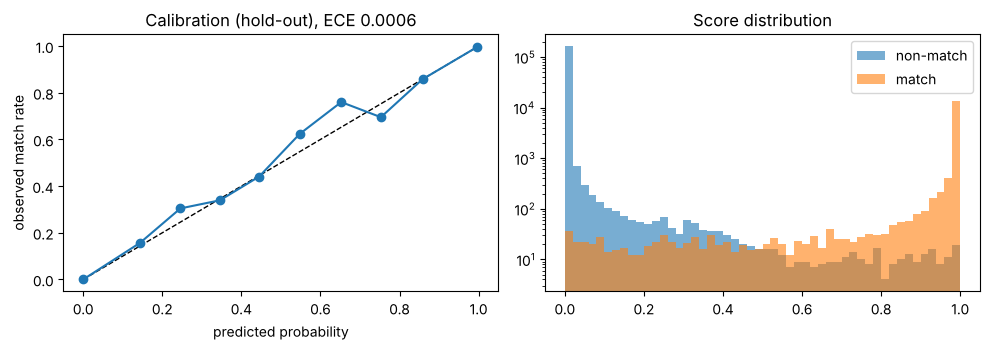

In [6]:
p_new = hold_scores[f"p{W}"]
base_p = hold_scores["hist_gbm"]
rb = evaluate("tuned", p_new, 0, {}); r0 = fam["hist_gbm"]
print(f"baseline (hist_gbm default): PR-AUC {r0['pr_auc']:.4f}  F0.5 {r0['macro_f05']:.4f} @ {r0['thr']:.2f}")
print(f"tuned ({GBDT}, w={W}):        PR-AUC {rb['pr_auc']:.4f}  F0.5 {rb['macro_f05']:.4f} @ {rb['thr']:.2f}")
_, fb = EU.macro_f05(ent_hold, ntrue, qH, yH, (base_p >= r0["thr"]).astype(int))
_, fn = EU.macro_f05(ent_hold, ntrue, qH, yH, (p_new >= rb["thr"]).astype(int))
dd = (fn - fb).values; bs = np.random.default_rng(SEED).choice(dd, (1000, len(dd)), replace=True).mean(1); lo, hi = np.percentile(bs, [2.5, 97.5])
print(f"paired bootstrap ΔF0.5 = {dd.mean():+.4f}  95% [{lo:+.4f}, {hi:+.4f}]")
USE_TUNED = bool(rb["pr_auc"] >= r0["pr_auc"] - 0.0005 and (tdf.iloc[0]["cv_pr_auc"] >= tune[json.dumps(DEFAULT, sort_keys=True)]["cv_pr_auc"]))
FINAL_FAMILY = GBDT if USE_TUNED else "hist_gbm"
FINAL_PARAMS = BEST if USE_TUNED else {"max_iter": 120, "learning_rate": 0.1, "max_leaf_nodes": 31}
FINAL_W = W if USE_TUNED else 1.0
print(f"DECISION: {'tuned configuration' if USE_TUNED else 'keep the Phase 5 baseline'} -> family {FINAL_FAMILY}, params {FINAL_PARAMS}, positive weight {FINAL_W}")

pf = hold_scores[f"p{W}"] if USE_TUNED else base_p
bins = np.linspace(0, 1, 11); idx = np.minimum((pf * 10).astype(int), 9)
cal = pd.DataFrame({"mean_pred": [pf[idx == k].mean() for k in range(10)], "frac_pos": [yH[idx == k].mean() for k in range(10)], "n": [(idx == k).sum() for k in range(10)]})
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].plot(cal["mean_pred"], cal["frac_pos"], marker="o"); ax[0].set_title(f"Calibration (hold-out), ECE {ece(yH, pf):.4f}")
ax[0].set_xlabel("predicted probability"); ax[0].set_ylabel("observed match rate")
ax[1].hist(pf[yH == 0], bins=50, alpha=.6, label="non-match", log=True); ax[1].hist(pf[yH == 1], bins=50, alpha=.6, label="match", log=True); ax[1].legend(); ax[1].set_title("Score distribution")
plt.tight_layout(); plt.show()

### 5b. Boosting vs. neural network vs. blend
The MLP had the best hold-out PR-AUC in section 2, so it is a real contender. Compare three final options on the hold-out:
**gbdt** (best boosted model above), **mlp** (default settings, section 2), **blend** (average of the two probabilities).
**Rule:** take the option with the highest PR-AUC (stable, all pairs); but if its best-threshold macro F0.5 is more than 0.003 below the best F0.5 among the options,
take the F0.5-best option instead. A paired bootstrap shows how much of the F0.5 difference is noise.

In [7]:
p_gb, p_mlp = pf, hold_scores["mlp"]
opts = {"gbdt": p_gb, "mlp": p_mlp, "blend": 0.5 * (p_gb + p_mlp)}
ores = {k: evaluate(k, v, 0, {}) for k, v in opts.items()}
odf = pd.DataFrame(ores).T[["pr_auc", "macro_f05", "thr", "logloss", "ece"]]; display(odf.round(4))
pick = odf["pr_auc"].idxmax()
if odf.loc[pick, "macro_f05"] < odf["macro_f05"].max() - 0.003: pick = odf["macro_f05"].idxmax()
FINAL_KIND = pick
f_ent = {k: EU.macro_f05(ent_hold, ntrue, qH, yH, (opts[k] >= ores[k]["thr"]).astype(int))[1].values for k in opts}
for k in ["mlp", "blend"]:
    d_ = f_ent[k] - f_ent["gbdt"]; b_ = np.random.default_rng(SEED).choice(d_, (1000, len(d_)), replace=True).mean(1)
    print(f"{k:6s} vs gbdt: ΔF0.5 {d_.mean():+.4f}  95% [{np.percentile(b_, 2.5):+.4f}, {np.percentile(b_, 97.5):+.4f}]")
print(f"FINAL CHOICE: {FINAL_KIND}")
FINAL_THR_DEV = ores[FINAL_KIND]["thr"]

,pr_auc,macro_f05,thr,logloss,ece
gbdt,0.9972,0.9504,0.55,0.0115,0.0006
mlp,0.9949,0.9451,0.70,0.0157,0.0012
blend,0.9971,0.9503,0.60,0.0119,0.0006


mlp    vs gbdt: ΔF0.5 -0.0053  95% [-0.0080, -0.0027]
blend  vs gbdt: ΔF0.5 -0.0001  95% [-0.0020, +0.0017]
FINAL CHOICE: gbdt


## 6. Train the final model(s) on all train queries and save
Fitted on all 24 k train queries (fit + hold-out). Validation scores are written for Phase 8 (threshold tuning) — **validation labels are not read here**.

final model(s) trained on 910,783 pairs in 95s: ['gbdt']


validation scores saved (227,888 rows); label column never read in this phase


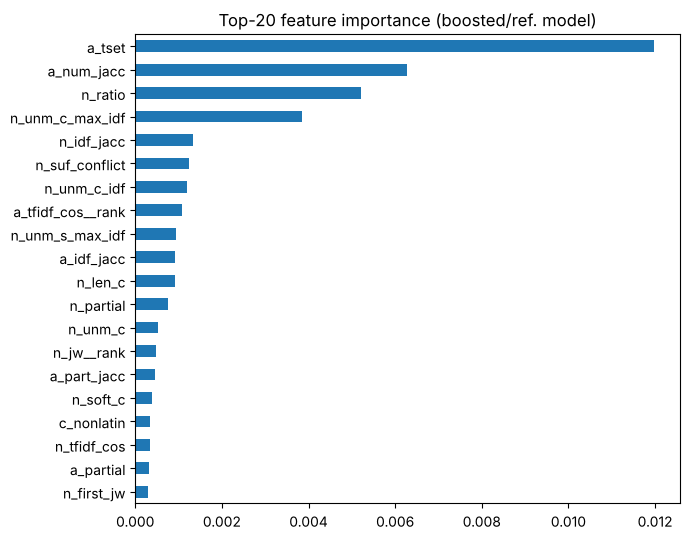

top features: ['a_tset', 'a_num_jacc', 'n_ratio', 'n_unm_c_max_idf', 'n_idf_jacc', 'n_suf_conflict', 'n_unm_c_idf', 'a_tfidf_cos__rank']


In [8]:
t0 = time.time(); score_parts = {}
Fva = pd.read_pickle(INTERIM + "/features_val.pkl")[FEATS]; Xv = Fva.values.astype(np.float32)
if FINAL_KIND in ("gbdt", "blend"):
    final = build(FINAL_PARAMS, FINAL_FAMILY).fit(X, y, sample_weight=np.where(y == 1, FINAL_W, 1.0))
    joblib.dump(final, "model_pair.joblib"); score_parts["gbdt"] = final.predict_proba(Xv)[:, 1]
if FINAL_KIND in ("mlp", "blend"):
    mlp = make_family("mlp").fit(X, y)
    joblib.dump(mlp, "model_mlp.joblib"); score_parts["mlp"] = mlp.predict_proba(Xv)[:, 1]
sv = np.mean(list(score_parts.values()), axis=0)
print(f"final model(s) trained on {len(y):,} pairs in {time.time()-t0:.0f}s: {list(score_parts)}")
json.dump(dict(kind=FINAL_KIND, gbdt=dict(family=FINAL_FAMILY, params=FINAL_PARAMS, positive_weight=FINAL_W) if "gbdt" in score_parts else None,
               mlp=dict(hidden=[128, 64], early_stopping=True, max_iter=40) if "mlp" in score_parts else None,
               blend="mean of probabilities" if FINAL_KIND == "blend" else None, features=FEATS, seed=SEED,
               holdout_80pct_model=dict(pr_auc=ores[FINAL_KIND]["pr_auc"], macro_f05=ores[FINAL_KIND]["macro_f05"], thr=FINAL_THR_DEV,
                                        note="optimistic: threshold tuned on the same hold-out; real threshold is chosen in Phase 8"),
               family_comparison=famdf[["pr_auc", "macro_f05", "secs"]].round(4).to_dict("index")), open("model_config.json", "w"), indent=2)
pd.DataFrame({"s1_id": pd.read_pickle(INTERIM + "/candidates_val.pkl")["s1_id"].values, "score": sv}).to_pickle(INTERIM + "/val_scores.pkl")
print(f"validation scores saved ({len(sv):,} rows); label column never read in this phase")

if "gbdt" in score_parts and FINAL_FAMILY == "lightgbm":
    imp = pd.Series(final.booster_.feature_importance("gain"), index=FEATS).sort_values(ascending=False)
else:
    from sklearn.inspection import permutation_importance
    s_ix = np.random.default_rng(0).choice(len(yH), 40_000, replace=False)
    ref = final if "gbdt" in score_parts else mlp
    pi = permutation_importance(ref, Xh[s_ix], yH[s_ix], n_repeats=2, random_state=0, scoring="average_precision", n_jobs=NJ)
    imp = pd.Series(pi.importances_mean, index=FEATS).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5.5)); imp.head(20)[::-1].plot.barh(ax=ax); ax.set_title("Top-20 feature importance (boosted/ref. model)"); plt.tight_layout(); plt.show()
print("top features:", imp.head(8).index.tolist())

## 7. Summary and hand-off

In [9]:
print("=== PHASE 7 SUMMARY ===")
print("Families (hold-out PR-AUC):", {k: round(v, 4) for k, v in famdf["pr_auc"].to_dict().items()})
print(f"Boosted model: {FINAL_FAMILY} {FINAL_PARAMS}, positive weight {FINAL_W}")
print("Options on hold-out:", {k: (round(v['pr_auc'], 4), round(v['macro_f05'], 4)) for k, v in ores.items()})
print(f"FINAL: {FINAL_KIND} | hold-out (80% model) PR-AUC {ores[FINAL_KIND]['pr_auc']:.4f}, best-threshold macro F0.5 {ores[FINAL_KIND]['macro_f05']:.4f} (optimistic)")
print("Saved: model_pair.joblib" + (", model_mlp.joblib" if "mlp" in score_parts else "") + ", model_config.json, dataset/interim/val_scores.pkl (scores only)")
print("Next: Phase 8 — tune the decision threshold on validation (macro F0.5), singleton handling, honest evaluation. Validation labels unused so far.")

=== PHASE 7 SUMMARY ===
Families (hold-out PR-AUC): {'mlp': 0.9949, 'hist_gbm': 0.9936, 'lightgbm': 0.9925, 'random_forest': 0.9922, 'logistic': 0.9753}
Boosted model: hist_gbm {'l2_regularization': 10.0, 'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 127, 'min_samples_leaf': 200}, positive weight 1.0
Options on hold-out: {'gbdt': (0.9972, 0.9504), 'mlp': (0.9949, 0.9451), 'blend': (0.9971, 0.9503)}
FINAL: gbdt | hold-out (80% model) PR-AUC 0.9972, best-threshold macro F0.5 0.9504 (optimistic)
Saved: model_pair.joblib, model_config.json, dataset/interim/val_scores.pkl (scores only)
Next: Phase 8 — tune the decision threshold on validation (macro F0.5), singleton handling, honest evaluation. Validation labels unused so far.
